# 03 Process scRNA-seq data


In [1]:
import scanpy as sc
from pathlib import Path
import pandas as pd
import requests
import tarfile

In [2]:
url = "https://github.com/bertis-informatics/msmu/releases/download/v0.4.3/GSE201575.tar.gz"
sdrf = f"https://github.com/bertis-informatics/msmu/releases/download/v0.4.3/sdrf.tsv"
base_dir = Path(url).name.split(".")[0]

r = requests.get(url)
r.raise_for_status()

with open(Path(url).name, "wb") as f:
    f.write(r.content)

with tarfile.open(Path(url).name, "r:gz") as tar:
    members = [m for m in tar.getmembers() if not Path(m.name).name.startswith("._")]
    tar.extractall(members=members, filter="data")

## Read the RNA count tables


In [3]:
path_list = Path(base_dir).glob("*.txt.gz")
path_list = sorted(path_list)
adata_list = []

for p in path_list:
    a = sc.read_text(p, delimiter="\t", first_column_names=True).T
    a.obs.index = [p.name]
    a.obs["filename"] = [p.stem]
    adata_list.append(a)

adata = sc.concat(adata_list)

## Add SDRF metadata and align cells


In [4]:
sdrf_df = pd.read_csv(sdrf, sep="\t", dtype=str)
rna_files = sdrf_df["factor value[rna data file]"]
cell_ids = sdrf_df["assay name"].to_list()

adata = adata[rna_files.to_list()].copy()
adata.obs = sdrf_df.set_index("factor value[rna data file]", drop=False)
adata.obs_names = cell_ids

adata

AnnData object with n_obs × n_vars = 70 × 40207
    obs: 'source name', 'characteristics[organism]', 'characteristics[organism part]', 'characteristics[disease]', 'characteristics[cell line]', 'characteristics[biological replicate]', 'assay name', 'technology type', 'comment[proteomics data acquisition method]', 'comment[label]', 'comment[instrument]', 'comment[cleavage agent details]', 'comment[modification parameters]', 'comment[modification parameters].1', 'comment[modification parameters].2', 'comment[fraction identifier]', 'comment[technical replicate]', 'comment[data file]', 'comment[file uri]', 'factor value[sample]', 'factor value[condition]', 'factor value[rna data file]'
    layers: None (.X)

### Inspect RNA count quality


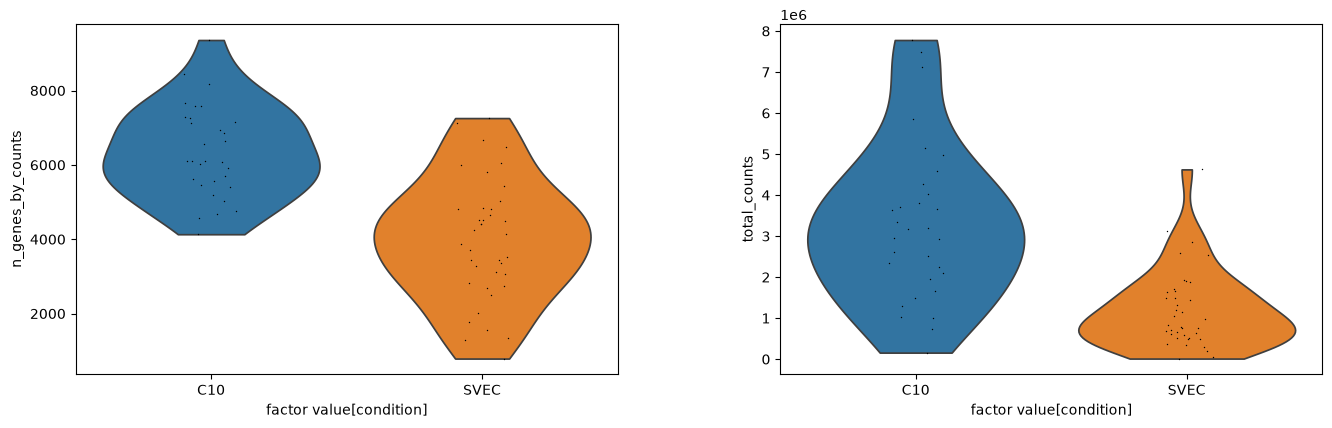

In [5]:
sc.pp.calculate_qc_metrics(adata, percent_top=None, inplace=True)
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts"], groupby="factor value[condition]", multi_panel=True)

## Filter and normalize RNA counts


In [6]:
adata.layers["counts"] = adata.X.copy()

sc.pp.filter_genes(adata, min_cells=3, inplace=True)
sc.pp.filter_cells(adata, min_genes=200, inplace=True)

sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

adata

AnnData object with n_obs × n_vars = 70 × 13451
    obs: 'source name', 'characteristics[organism]', 'characteristics[organism part]', 'characteristics[disease]', 'characteristics[cell line]', 'characteristics[biological replicate]', 'assay name', 'technology type', 'comment[proteomics data acquisition method]', 'comment[label]', 'comment[instrument]', 'comment[cleavage agent details]', 'comment[modification parameters]', 'comment[modification parameters].1', 'comment[modification parameters].2', 'comment[fraction identifier]', 'comment[technical replicate]', 'comment[data file]', 'comment[file uri]', 'factor value[sample]', 'factor value[condition]', 'factor value[rna data file]', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'factor value[condition]_colors', 'log1p'
    layers: None (.X), 

## Save the RNA modality


In [7]:
adata.write_h5ad("GSE201575.h5ad")